# Data Prep and EDA

1. Download the **German Credit ESMT** dataset from Canvas. 

2. Load the data to a `DataFrame`

3. Explore it

Column headers should be self-explanatory. Our **target** is `credit_risk` (i.e., rightmost column).

## Plan for action for our data audit

- Look at first 5 rows
- Count missing values
- Check data types
- Check shape of data and what columns (aka features) we have got
- Distribution of the outcome
- Distribution of the features



### Data loading and first-level analysis 

In [75]:
import pandas as pd
# load the German Credit dataset
df = pd.read_csv("../data/GermanCreditESMT.csv")

print("Shape of the dataset:", df.shape)  # (1000, 21)
display(df.head(5))

Shape of the dataset: (1000, 21)


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,no checking account,18,all credits at this bank paid back duly,car (used),1049,unknown/no savings account,< 1 yr,< 20,female : non-single or male : single,none,...,car or other,21,none,for free,1,skilled employee/official,0 to 2,no,no,good
1,no checking account,9,all credits at this bank paid back duly,others,2799,unknown/no savings account,1 <= ... < 4 yrs,25 <= ... < 35,male : married/widowed,none,...,unknown / no property,36,none,for free,2-3,skilled employee/official,3 or more,no,no,good
2,... < 0 DM,12,no credits taken/all credits paid back duly,retraining,841,... < 100 DM,4 <= ... < 7 yrs,25 <= ... < 35,female : non-single or male : single,none,...,unknown / no property,23,none,for free,1,unskilled - resident,0 to 2,no,no,good
3,no checking account,12,all credits at this bank paid back duly,others,2122,unknown/no savings account,1 <= ... < 4 yrs,20 <= ... < 25,male : married/widowed,none,...,unknown / no property,39,none,for free,2-3,unskilled - resident,3 or more,no,yes,good
4,no checking account,12,all credits at this bank paid back duly,others,2171,unknown/no savings account,1 <= ... < 4 yrs,< 20,male : married/widowed,none,...,car or other,38,bank,rent,2-3,unskilled - resident,0 to 2,no,yes,good


In [76]:
# Data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   status                   1000 non-null   str  
 1   duration                 1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   amount                   1000 non-null   int64
 5   savings                  1000 non-null   str  
 6   employment_duration      1000 non-null   str  
 7   installment_rate         1000 non-null   str  
 8   personal_status_sex      1000 non-null   str  
 9   other_debtors            1000 non-null   str  
 10  present_residence        1000 non-null   str  
 11  property                 1000 non-null   str  
 12  age                      1000 non-null   int64
 13  other_installment_plans  1000 non-null   str  
 14  housing                  1000 non-null   str  
 15  number_credits  

### Distribution of the binary target


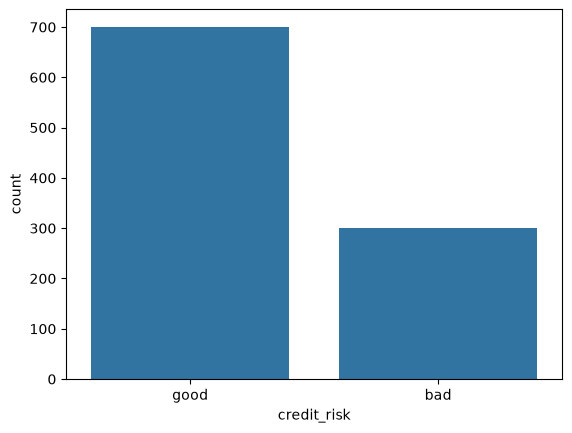

In [77]:
import seaborn as sns
import matplotlib.pyplot as plt
# Visualize the distribution of the target variable
sns.countplot(x='credit_risk', data=df)
plt.show()

### Distribution of the numerical features
We routinely use *histograms* and *box-plots* to examine the distribution of a single feature. Make sure you are familiar with these instruments

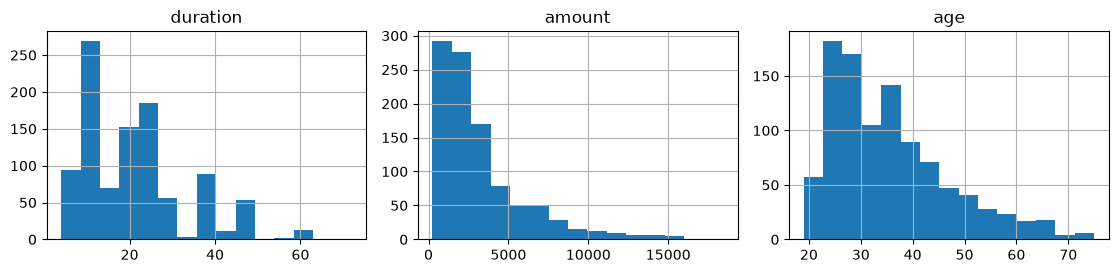

In [78]:
# histograms for numeric features
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns
df[numeric_features].hist(bins=15, figsize=(15, 10), layout=(4, 4))
plt.tight_layout()

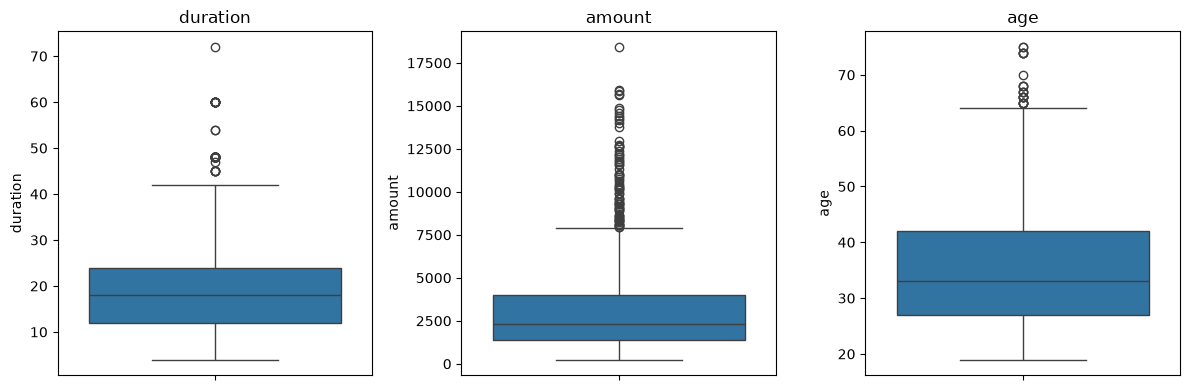

In [79]:
# Boxplot for numeric features
plt.figure(figsize=(12 ,4))
for i, feature in enumerate(numeric_features):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[feature])
    plt.title(feature)
plt.tight_layout()

## Categorical features
To analyze the categorical features, the *count plot* is a popular instrument. 

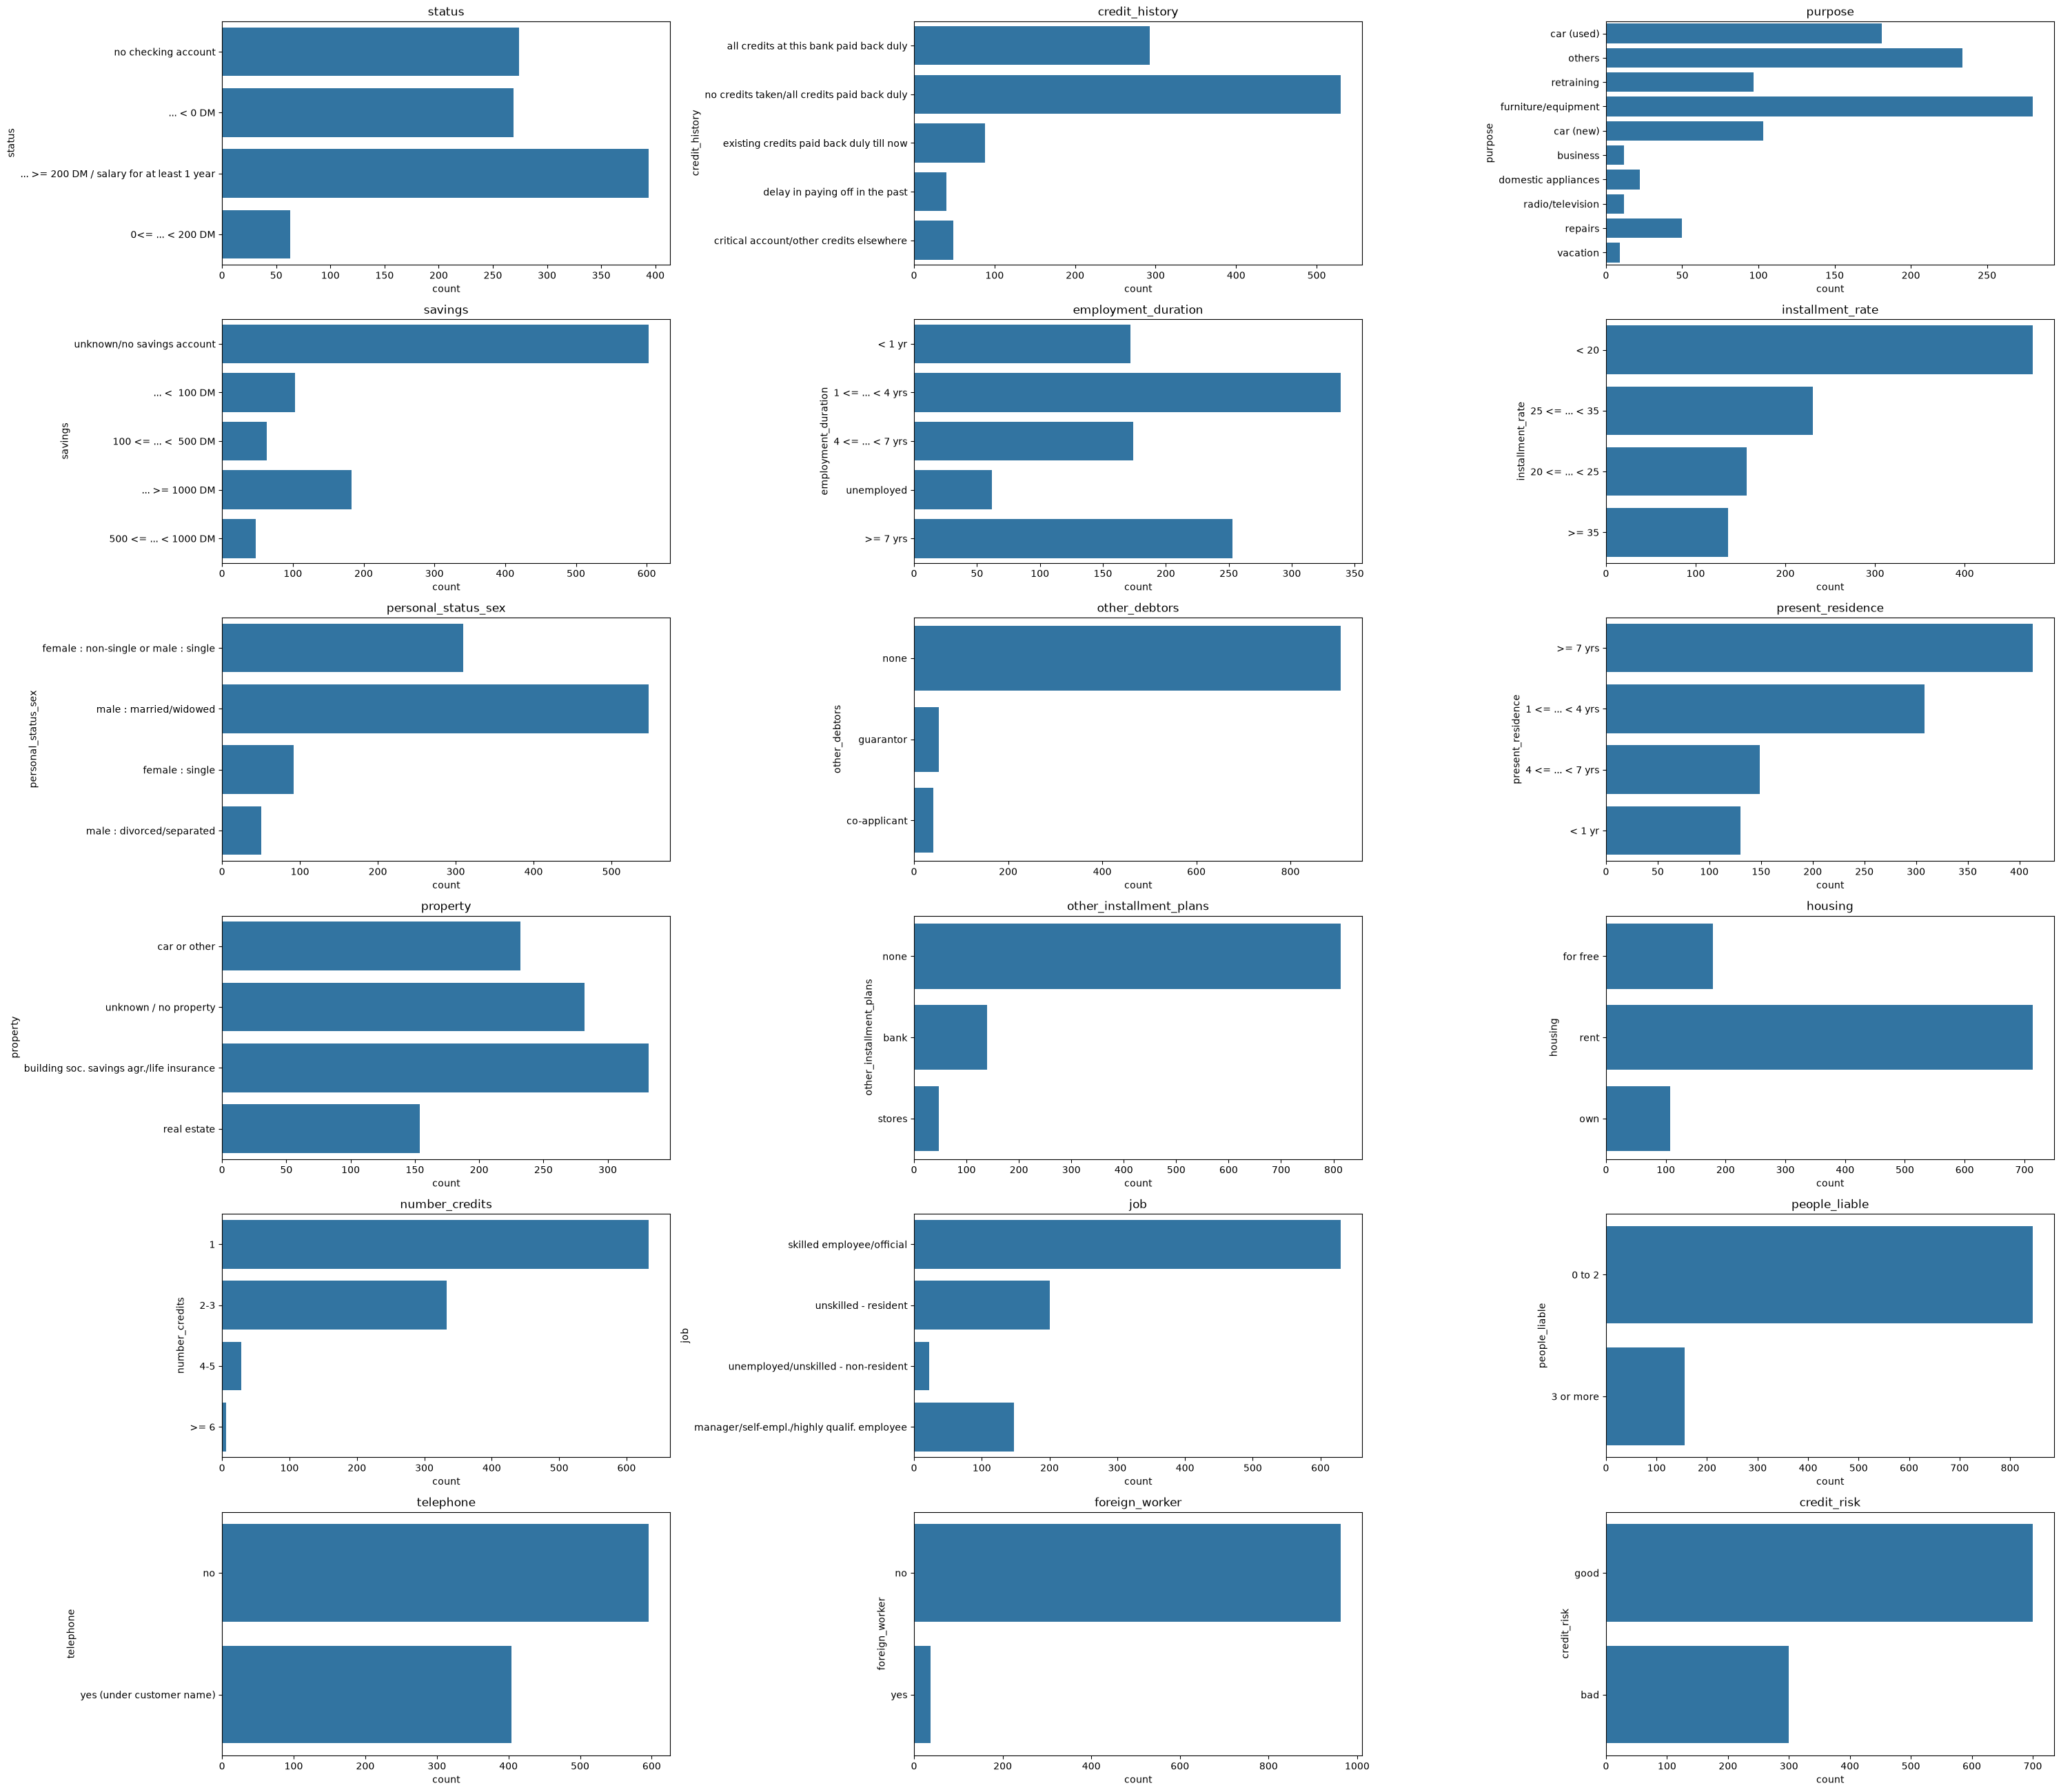

In [80]:
# Countplots for all categorical features
categorical_features = df.select_dtypes(include=['str']).columns
plt.figure(figsize=(30, 30))
for i, feature in enumerate(categorical_features):
    plt.subplot(7, 3, i + 1)
    sns.countplot(y=df[feature])
    plt.title(feature)
    plt.tight_layout()
plt.show()

# Making plots more informative
In classification problems, particulaly binary classification, charts to examine the distribution of a feature can be more informative when they show how feature values are distributed across different levels of the target. The *seaborn* library provides an easy to use way to adjust plots accordingly. Many *seaborn* functions provide an argument `hue`, which you can use to stratify plots by a given feature. Set this argument equal to the modeling target to stratify plots by the target classes. 

Below, we re-create the previous plots with `hue=y`to illustrate this approach.

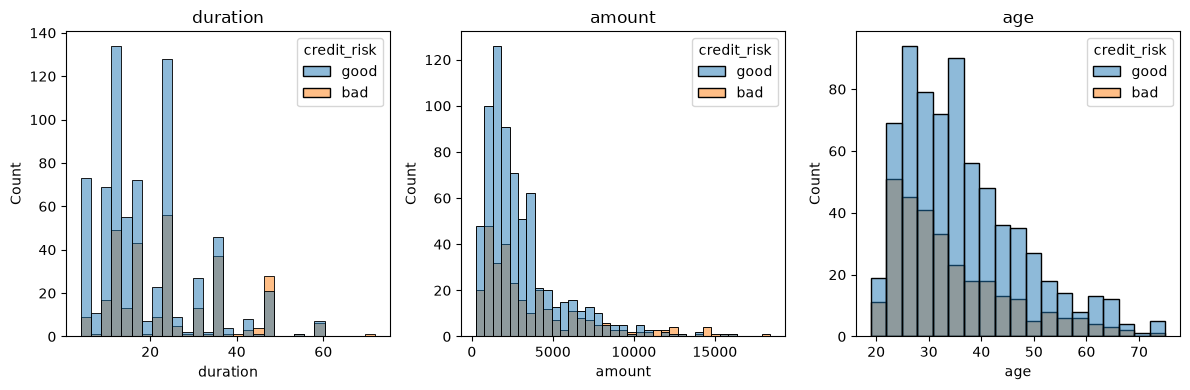

In [81]:
# histograms for numeric features stratified by target variable
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns
plt.figure(figsize=(12, 4))
for i, feature in enumerate(numeric_features):
    plt.subplot(1, 3, i + 1)
    sns.histplot(x=df[feature],  hue=df["credit_risk"])
    plt.title(feature)
    plt.tight_layout()
plt.show()


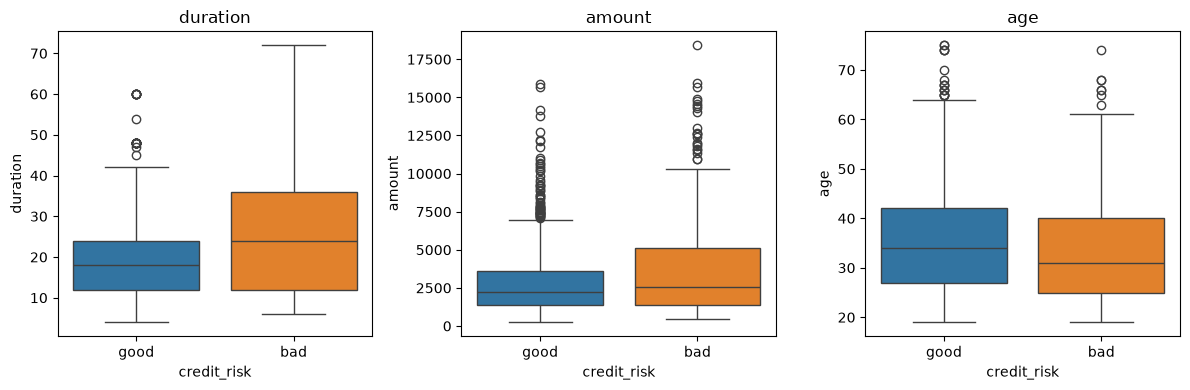

In [82]:
# boxplots for numeric features stratified by target variable
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns
plt.figure(figsize=(12, 4))
for i, feature in enumerate(numeric_features):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(x=df["credit_risk"], y=df[feature], hue=df["credit_risk"])
    plt.title(feature)
    plt.tight_layout()
plt.show()


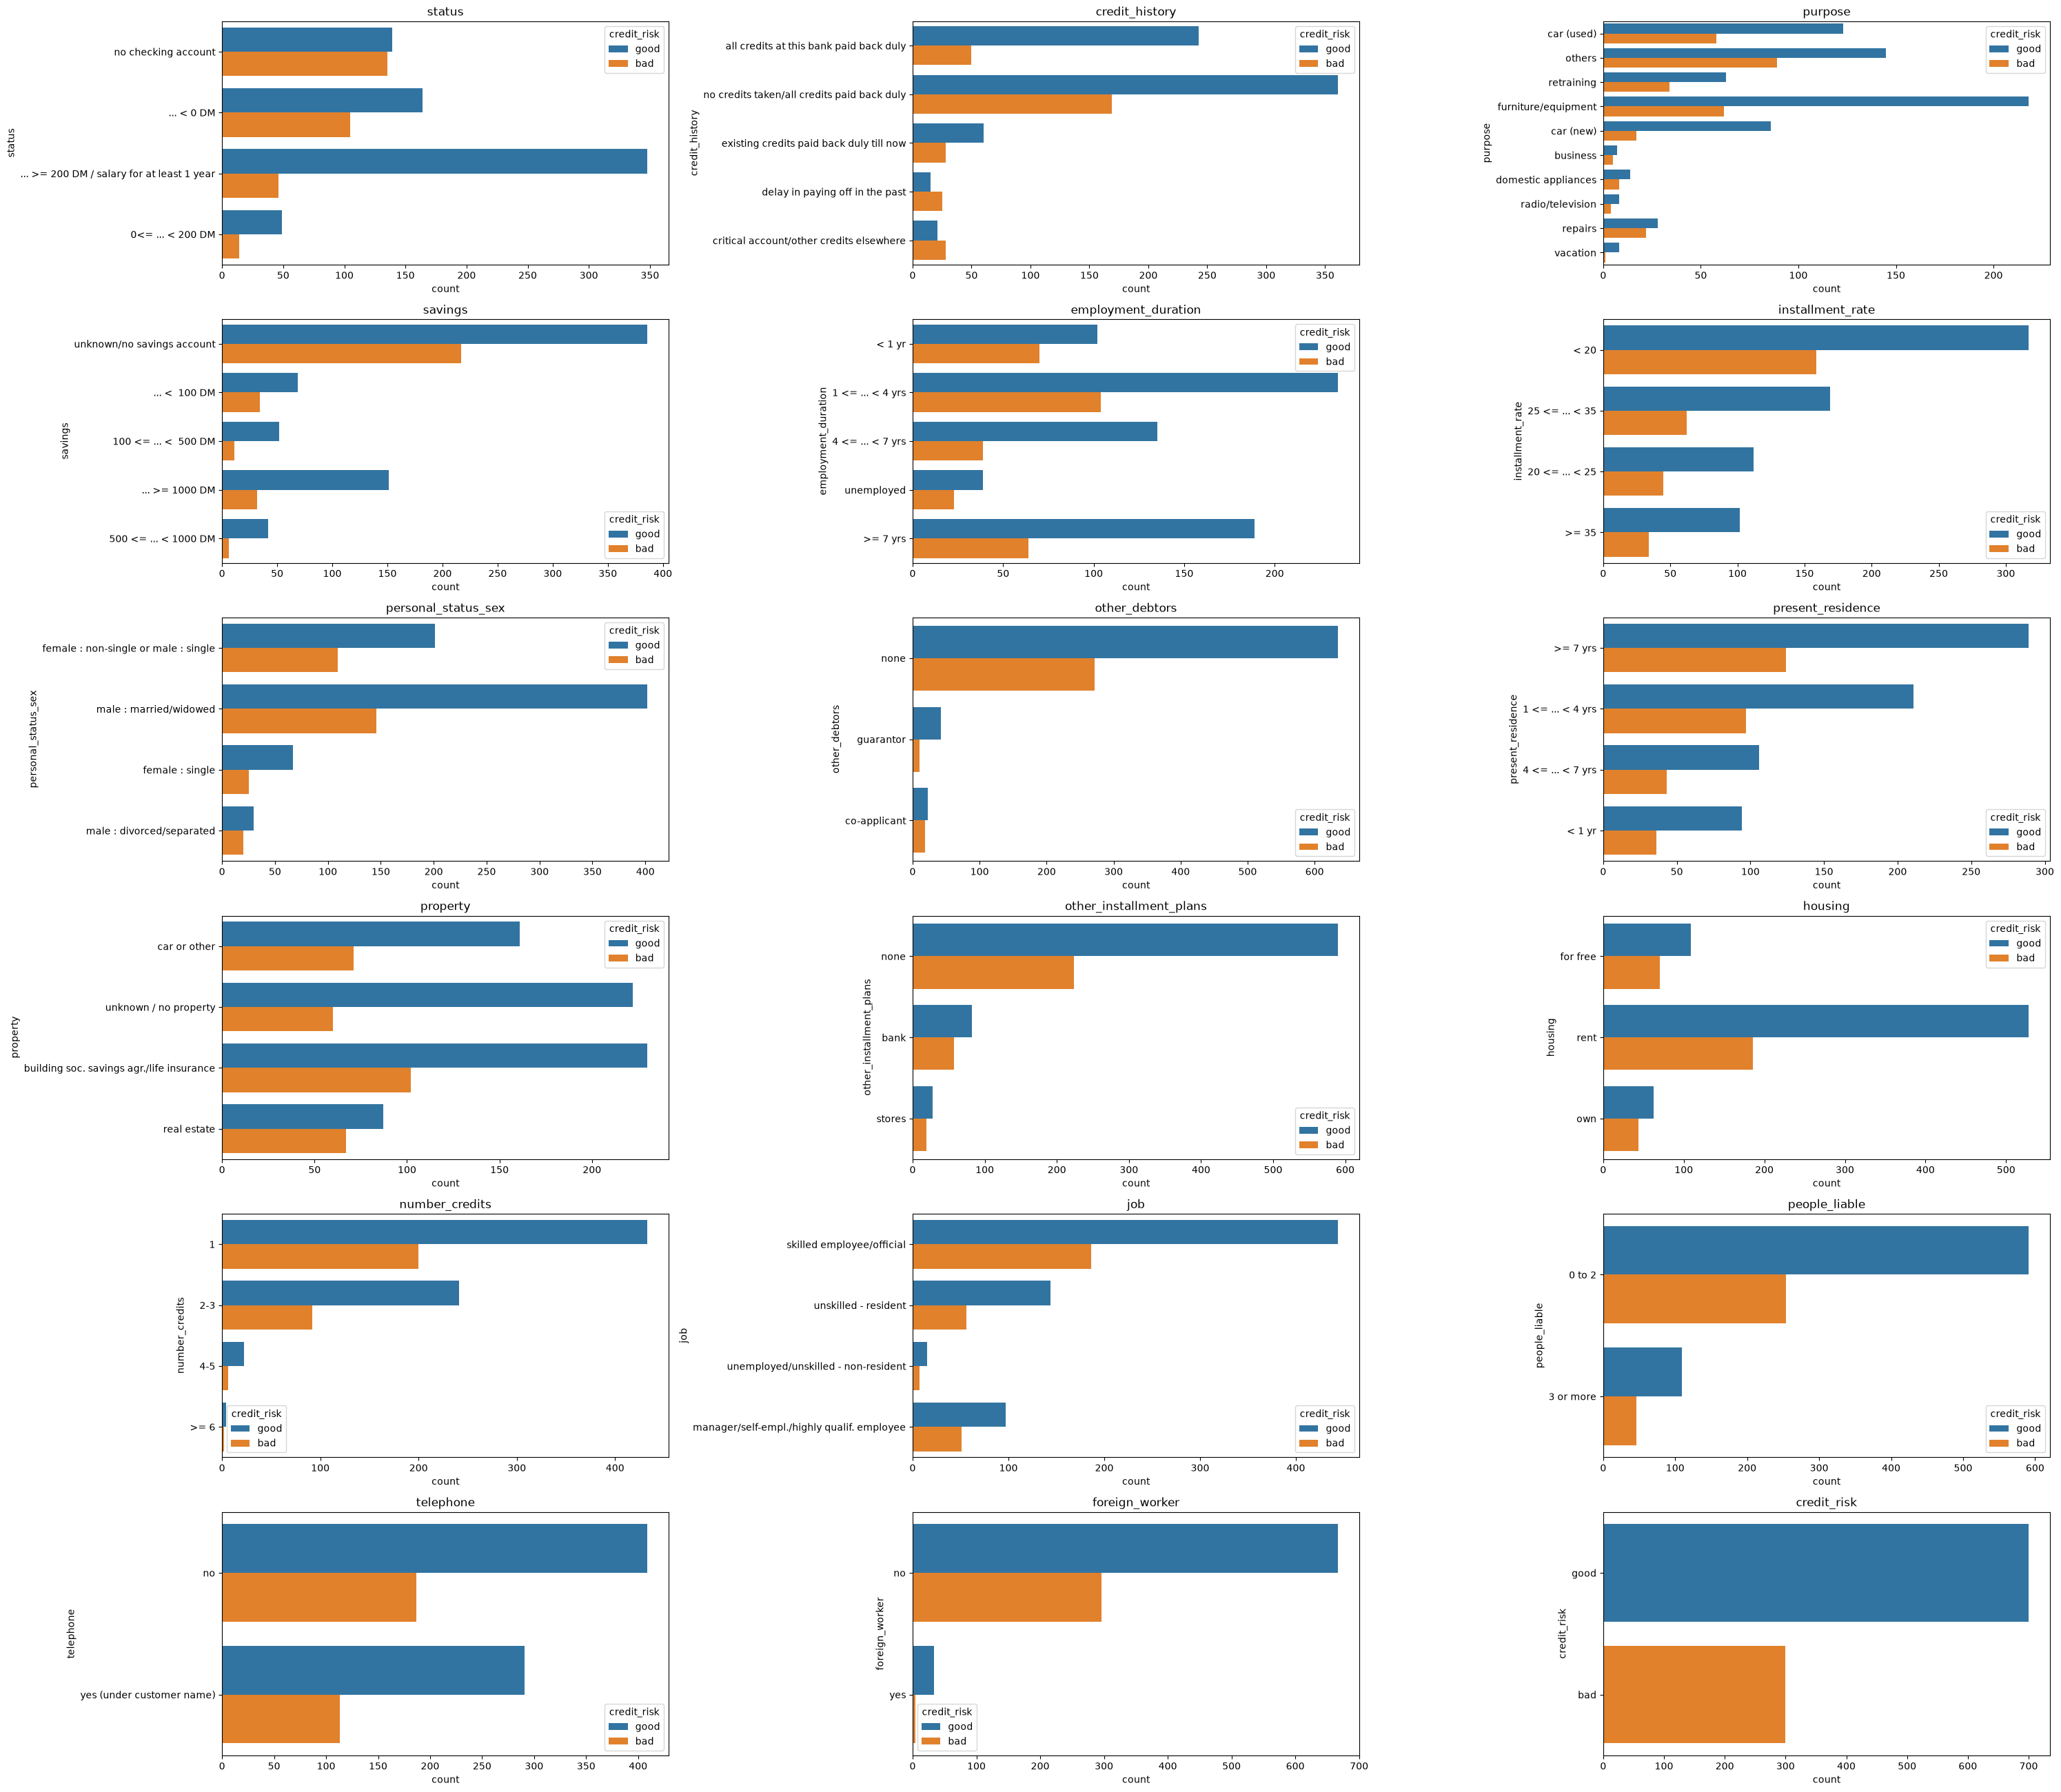

In [83]:
# Countplots stratified by target variable for all categorical features
categorical_features = df.select_dtypes(include=['str']).columns
plt.figure(figsize=(30, 30))
for i, feature in enumerate(categorical_features):
    plt.subplot(7, 3, i + 1)
    sns.countplot(y=df[feature],  hue=df["credit_risk"])
    plt.title(feature)
    plt.tight_layout()
plt.show()

## Examining pairs of features
All previous plots shed light on one feature individually. Standard ways to examine pairs of features include the *scatter plot* and the *correlation matrix*, which depicts all pairwise correlations between all features in a dataset. These visualizations are restricted to numerical features. Let's check them out. 

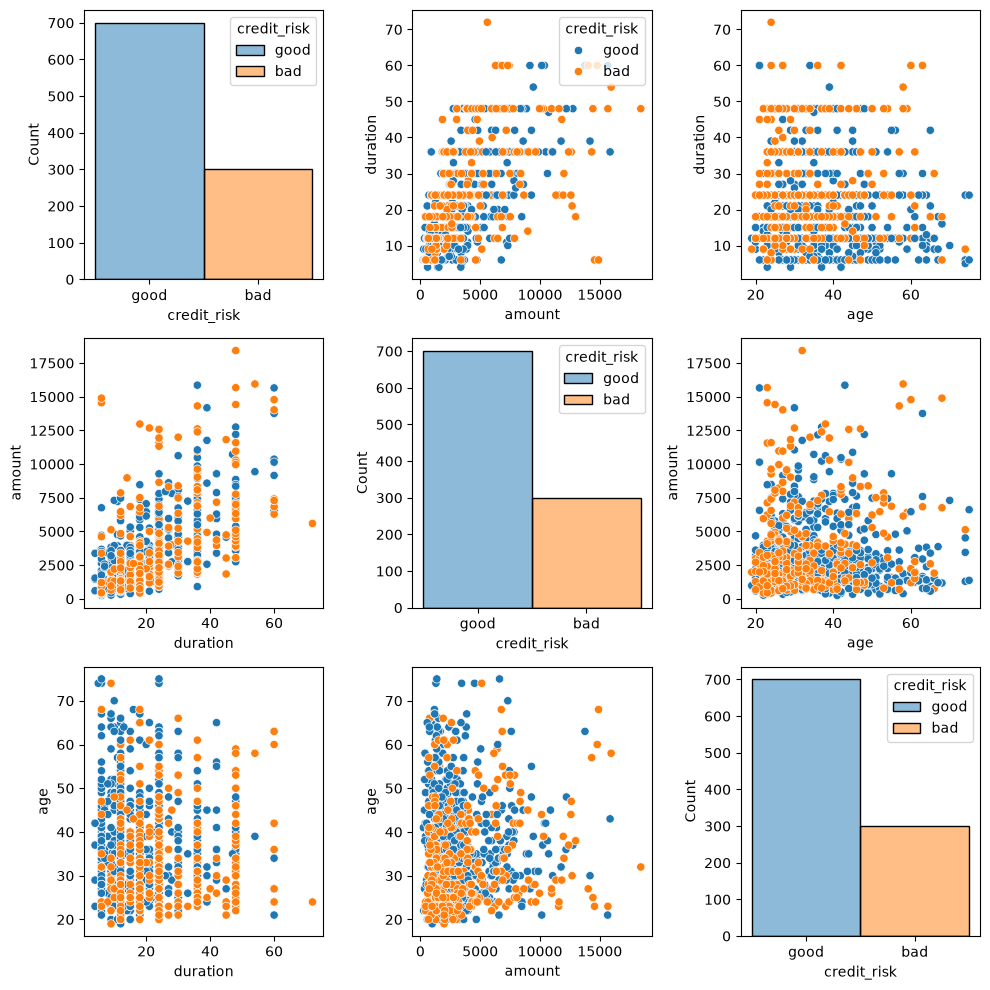

In [84]:
# Scatter-plot matrix for numeric feature pairs, stratified by target
n_features = len(numeric_features)
fig, axes = plt.subplots(n_features, n_features, figsize=(10, 10))

for row, y_feature in enumerate(numeric_features):
    for col, x_feature in enumerate(numeric_features):
        ax = axes[row, col]

        if row == col:
            sns.histplot(x=df[feature],  hue=df["credit_risk"], ax=ax)  # This is the main diagonal, so we plot a histogram. You can select another univariate plot if you prefer.
        else:
            sns.scatterplot(
                data=df,
                x=x_feature,
                y=y_feature,
                hue="credit_risk",
                ax=ax,
                legend=(row == 0 and col == 1)
            )

plt.tight_layout()
plt.show()

Note that, because the analysis just shown is very common, *seaborn* provides an easy to use function to the pairwise analysis without having to code the nested loop through feature pairs manually. It's called `pairplot`. In the below demo, examine the options for the argument `kind` and try out a feature different options.

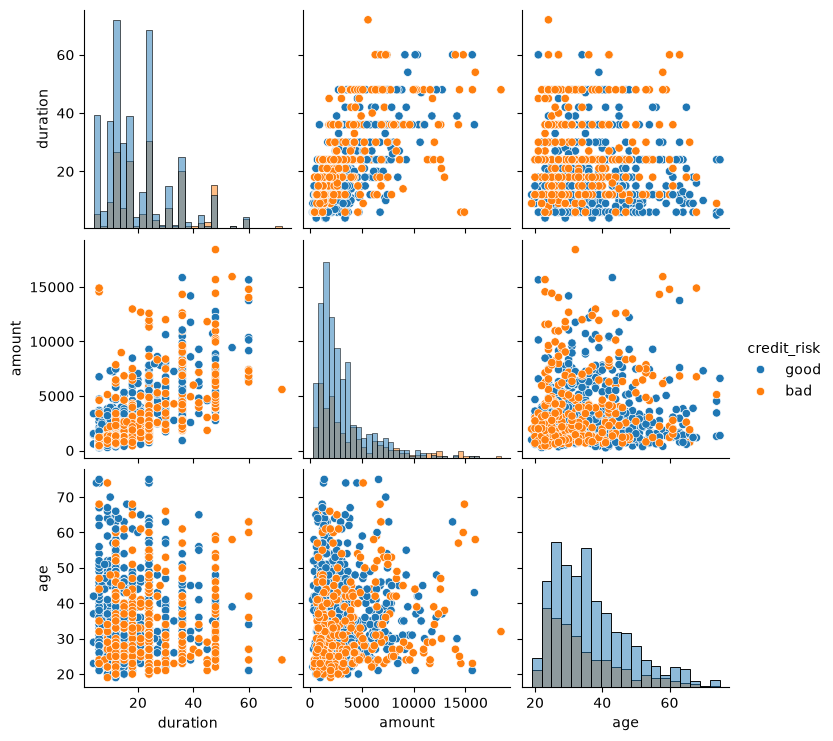

In [85]:
sns.pairplot(
    data=df,
    vars=numeric_features,
    hue="credit_risk",
    kind="scatter",
    diag_kind="hist"
)
plt.show()

### Pairwise correlation

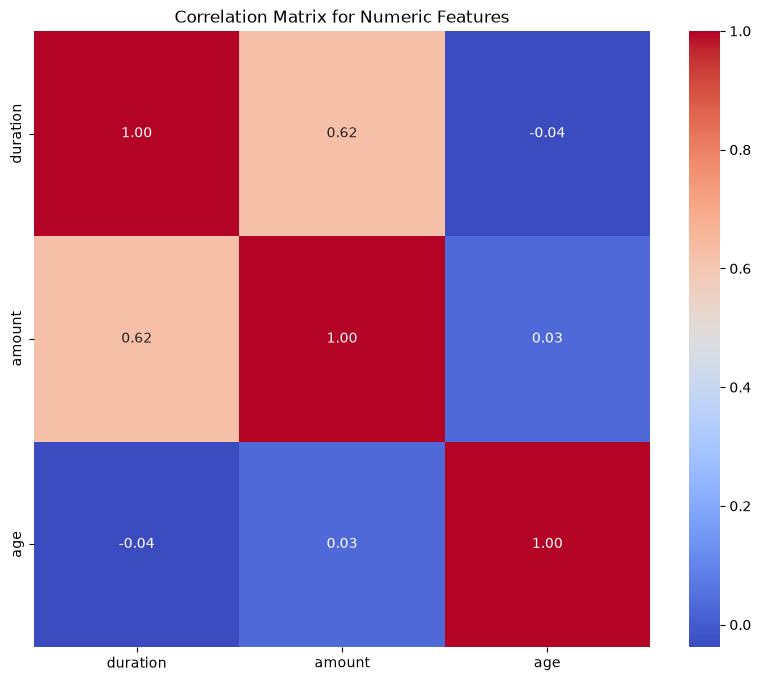

In [86]:
# Correlation matrix for numeric features
correlation_matrix = df[numeric_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title("Correlation Matrix for Numeric Features")
plt.show()

## Encoding the categorical features
Most of the features in the dataset are categories. Many ML methods including regression-type methods do not allow you to use categorical data in its raw form. More specifically, our dataset stores different values, called *levels* of a categorical variable as a text. You cannot run a regression on a textual feature. In theory, you could address this easily: just assign consecutive numbers to the different levels of the categorical feature. Here is an illustration:

0    3
1    3
2    0
3    3
4    3
dtype: int8

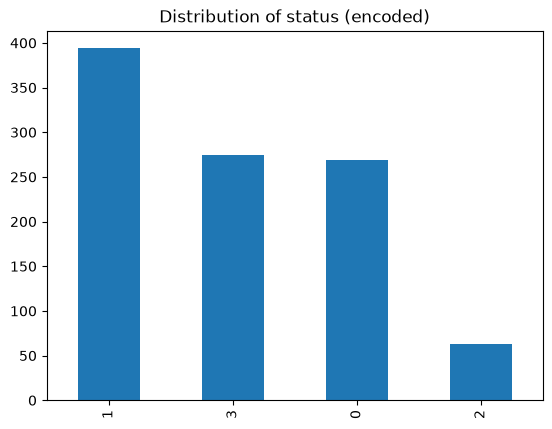

In [87]:
feature = "status"  # Select a categorical features
# Encode the feature using consecutive numbers 
demo = df[feature].astype('category').cat.codes
display(demo.head())
demo.value_counts().plot(kind='bar', title=f"Distribution of {feature} (encoded)")
plt.show()


Unfortunately, this simply way to address the categories is typically inappropriate and can introduce spurious patters in your dataset. Note that the numeric codes imply an ordering among the category levels and also different distances between one level and another. This is exactly the information that a categorical feature **does not** embody. Your codes introduce artificially.

The standard way to encode categorical features is called *dummy coding* or *one-hot coding* and introduces a new binary feature for each level of the categorical feature. The new features are called *dummy variables*. There are two common ways to implement this in Python. The first is to use the `get_dummies` function from the `pandas` library. The second is to use the `OneHotEncoder` class from the `sklearn.preprocessing` module. Let's illustrate both approaches.

In [88]:
# Dummy coding / one-hot encoding for all categorical features using Pandas `get_dummies` function
categorical_features = df.select_dtypes(include=['str']).columns
df_enc_pandas = pd.get_dummies(df, columns=list(categorical_features), drop_first=True)
df_enc_pandas.head()

,duration,amount,age,status_... >= 200 DM / salary for at least 1 year,status_0<= ... < 200 DM,status_no checking account,credit_history_critical account/other credits elsewhere,credit_history_delay in paying off in the past,credit_history_existing credits paid back duly till now,credit_history_no credits taken/all credits paid back duly,...,number_credits_2-3,number_credits_4-5,number_credits_>= 6,job_skilled employee/official,job_unemployed/unskilled - non-resident,job_unskilled - resident,people_liable_3 or more,telephone_yes (under customer name),foreign_worker_yes,credit_risk_good
0,18,1049,21,False,False,True,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
1,9,2799,36,False,False,True,False,False,False,False,...,True,False,False,True,False,False,True,False,False,True
2,12,841,23,False,False,False,False,False,False,True,...,False,False,False,False,False,True,False,False,False,True
3,12,2122,39,False,False,True,False,False,False,False,...,True,False,False,False,False,True,True,False,True,True
4,12,2171,38,False,False,True,False,False,False,False,...,True,False,False,False,False,True,False,False,True,True


In [89]:
from sklearn.preprocessing import OneHotEncoder

categorical_cols = df.select_dtypes(include=["object", "string", "category"]).columns
# The actual encoding happens in the next two lines
encoder = OneHotEncoder(handle_unknown="ignore", drop="first")
codes = encoder.fit_transform(df[categorical_cols])

# However, we need a bit more work to get the results back into a DataFrame
print("Type of the encoded data:", type(codes))  # Note the 'funny' data type of the encoded data. It is a sparse matrix, which is a memory-efficient way to store data that contains a lot of zeros. We need to convert it to a dense format and then create a DataFrame with appropriate column names.
encoded = pd.DataFrame(
    codes.toarray(),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=df.index,
)

df_encoded = pd.concat(
    [df.drop(columns=categorical_cols), encoded],
    axis=1,
)
df_encoded

Type of the encoded data: <class 'scipy.sparse._csr.csr_matrix'>


,duration,amount,age,status_... >= 200 DM / salary for at least 1 year,status_0<= ... < 200 DM,status_no checking account,credit_history_critical account/other credits elsewhere,credit_history_delay in paying off in the past,credit_history_existing credits paid back duly till now,credit_history_no credits taken/all credits paid back duly,...,number_credits_2-3,number_credits_4-5,number_credits_>= 6,job_skilled employee/official,job_unemployed/unskilled - non-resident,job_unskilled - resident,people_liable_3 or more,telephone_yes (under customer name),foreign_worker_yes,credit_risk_good
0,18,1049,21,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,9,2799,36,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
2,12,841,23,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,12,2122,39,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
4,12,2171,38,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,24,1987,21,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
996,24,2303,45,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
997,21,12680,30,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
998,12,6468,52,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


You can see that both approaches give the same results. The `OneHotEncoder` examples looks more complicated. If you really want the encoded data to remain in a `DataFrame`, the `get_dummies` function is more convenient choice. However, `OneHotEncoder` offers additional functionality not demonstrated here. So it is the more powerful variant, and you will see that most published/generated codes make use of it as opposed to `get_dummies`. 

Lastly, note the *explosion* in dimensionality that occurs when you encode categorical features. This is a common problem with categorical features. Better, or more specialized forms of encoding exist and can avoid this problem in specific settings (e.g., forecasting settings). If you are curious, run a web search for *Target Encoding* or *Mean Encoding*. However, these more advanced techniques are beyond the scope of this session.

In [90]:
print("Before dummy encoding:", df.shape)
print("After dummy encoding:", df_encoded.shape)

Before dummy encoding: (1000, 21)
After dummy encoding: (1000, 55)
